# Assignment 2: Transformer language models

[Official instructions](https://liu-nlp.ai/dl4nlp/units/a1_2.html)

Run this notebook from top to bottom. All implementation code is included here.
The shared tokenizer is reused if Assignment 1 created it in `dl4nlp_data`; otherwise
it is built from training text. The training defaults match Assignment 1.
`QUICK_RUN=True` uses a small subset for development. Full results require `False`.


## Step 0: Environment and shared utilities


In [1]:
# Install the packages in this notebook's Python kernel; version bounds keep the APIs compatible.
# After the first installation, restart the kernel if Jupyter asks you to.
%pip install -q "torch>=2.6,<3" "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" "nltk>=3.9,<4" "pandas>=2,<4" "matplotlib>=3.8,<4" "tqdm>=4.66" "certifi>=2024.2.2"



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the libraries for data preparation, neural networks, and displaying results.
import gc
import json
import math
import time
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown, FileLink
from transformers import BatchEncoding, PretrainedConfig, PreTrainedModel, TrainingArguments, set_seed
from transformers.modeling_outputs import CausalLMOutput

pd.set_option('display.max_colwidth', 140)

# Use a CUDA GPU when available, otherwise Apple MPS, otherwise the CPU.
def select_device(use_cpu=False):
    if use_cpu:
        return torch.device('cpu')
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


/Users/echaefs/Documents/Code/tdde09/dl4nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Choose corpus, vocabulary and training settings for the Transformer.
QUICK_RUN = False  # True checks a small subset; False runs the full experiment.
FORCE_CPU = False
SEED = 101
# The vocabulary cap includes PAD, UNK, BOS and EOS.
VOCAB_SIZE = 10000
# Maximum tokens per paragraph, including its boundary tokens.
MAX_LENGTH = 128
# Process this many paragraphs together in each optimizer step.
BATCH_SIZE = 32
EPOCHS = 1 if QUICK_RUN else 3
# Step size for AdamW; large values can make training unstable.
LEARNING_RATE = 3e-4
QUICK_TRAIN_SAMPLES, QUICK_VAL_SAMPLES = 1000, 200
EMBEDDING_SIZE, HIDDEN_SIZE = 128, 256
DATA_DIR = Path('dl4nlp_data')
# This folder holds the checkpoint used later by from_pretrained, plus optional logs.
OUTPUT_DIR = Path('outputs') / ('assignment2_quick' if QUICK_RUN else 'assignment2')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = select_device(FORCE_CPU)
# Fix random seeds for a repeatable run on the same setup.
set_seed(SEED)
print('Device:', DEVICE, '| Mode:', 'small subset' if QUICK_RUN else 'full experiment')


Device: mps | Mode: full experiment


In [4]:
# Set the Transformer depth/width and the sampling settings used for both generation comparisons.
NUM_LAYERS, NUM_HEADS, INTERMEDIATE_SIZE = 2, 4, 688
OLMO_MODEL_NAME = 'allenai/OLMo-2-0425-1B'
MAX_NEW_TOKENS = 50
# Lower temperature concentrates probability on likely tokens; top-k limits the candidate set.
TEMPERATURES, TOP_K_VALUES = [0.7, 1.0, 1.3], [10, 40]
PROMPTS = [
    'In natural language processing, a Transformer',
    'Is Stockholm the capital of Sweden? Answer yes or no. The answer is',
    'Write a Python program that reverses a list.',
]


In [5]:
# Reuse the Assignment 1 corpus, downloading it with verified HTTPS only when needed.
import ssl
import certifi

# Add trusted CA certificates for Python installations without a configured CA bundle.
download_context = ssl.create_default_context()
download_context.load_verify_locations(cafile=certifi.where())

DATA_URL = 'https://www.cse.chalmers.se/~richajo/waspnlp2026/a1_1.zip'
# Keep training and validation text separate; vocabulary statistics use training text only.
TRAIN_FILE, VAL_FILE = DATA_DIR / 'train.txt', DATA_DIR / 'val.txt'
if not TRAIN_FILE.exists() or not VAL_FILE.exists():
    archive_path = DATA_DIR / 'a1_1.zip'
    if not archive_path.exists():
        print('Downloading the official corpus...')
        with urllib.request.urlopen(DATA_URL, timeout=60, context=download_context) as response:
            archive_path.write_bytes(response.read())
    # Extract the two text files; rerunning the cell reuses files already downloaded.
    with zipfile.ZipFile(archive_path) as archive:
        for name in ('train.txt', 'val.txt'):
            (DATA_DIR / name).write_bytes(archive.read(f'a1_1/{name}'))
print('Training file:', TRAIN_FILE)
print('Validation file:', VAL_FILE)


Training file: dl4nlp_data/train.txt
Validation file: dl4nlp_data/val.txt


### Tokenizer reused from Assignment 1
These definitions make the notebook independent of external Python files.


In [6]:
# Reuse the word tokenizer from Assignment 1; its definitions are included so this notebook stands alone.
def lowercase_tokenizer(text):
    # Paragraphs are already separate examples, so no sentence model is needed.
    return [word.lower() for word in nltk.word_tokenize(text, preserve_line=True)]


def build_tokenizer(train_file, tokenize_fun=lowercase_tokenizer,
                    max_voc_size=10000, model_max_length=128,
                    pad_token='<PAD>', unk_token='<UNK>',
                    bos_token='<BOS>', eos_token='<EOS>'):
    special = [pad_token, unk_token, bos_token, eos_token]
    if len(set(special)) != 4:
        raise ValueError('The four special tokens must be distinct.')
    if max_voc_size is not None and max_voc_size < 4:
        raise ValueError('max_voc_size must allow the four special tokens.')
    # Count each word in the training corpus; frequent words receive vocabulary entries.
    counts = Counter()
    with open(train_file, encoding='utf-8') as stream:
        for line in tqdm(stream, desc='Building training vocabulary'):
            if line.strip():
                counts.update(tokenize_fun(line))
    # Avoid assigning an ordinary-word entry to a reserved special token.
    for token in special:
        counts.pop(token, None)
    # Reserve four slots before choosing the most frequent ordinary words.
    limit = None if max_voc_size is None else max_voc_size - 4
    words = special + [word for word, _ in counts.most_common(limit)]
    return A1Tokenizer(words, model_max_length, tokenize_fun)


class A1Tokenizer:
    def __init__(self, words, model_max_length=128,
                 tokenize_fun=lowercase_tokenizer):
        if len(words) < 4 or len(words) != len(set(words)):
            raise ValueError('Vocabulary needs four distinct special tokens and unique words.')
        if model_max_length < 2:
            raise ValueError('model_max_length must allow BOS and EOS.')
        # Keep both directions: words to IDs for the model, IDs to words for inspection.
        self.str_to_int = {word: i for i, word in enumerate(words)}
        self.int_to_str = dict(enumerate(words))
        # The first four vocabulary entries have fixed meanings across all batches.
        self.pad_token_id, self.unk_token_id = 0, 1
        self.bos_token_id, self.eos_token_id = 2, 3
        self.model_max_length = model_max_length
        self.tokenize_fun = tokenize_fun

    def encode(self, text, truncation=False, add_eos=True):
        # Map words outside the vocabulary to the UNK ID.
        ids = [self.str_to_int.get(word, self.unk_token_id)
               for word in self.tokenize_fun(text)]
        if truncation:
            # Leave room for BOS and, when requested, EOS during truncation.
            ids = ids[:self.model_max_length - 1 - int(add_eos)]
        return [self.bos_token_id] + ids + ([self.eos_token_id] if add_eos else [])

    def pad(self, sequences, return_tensors='pt'):
        # Pad to the longest example in this batch, so all rows have equal length.
        width = max(map(len, sequences), default=0)
        ids = [seq + [self.pad_token_id] * (width - len(seq)) for seq in sequences]
        # The attention mask is 1 for actual tokens and 0 for the added padding.
        mask = [[1] * len(seq) + [0] * (width - len(seq)) for seq in sequences]
        return BatchEncoding({'input_ids': ids, 'attention_mask': mask},
                             tensor_type=return_tensors)

    def __call__(self, texts, truncation=False, padding=False, return_tensors=None):
        if return_tensors not in (None, 'pt'):
            raise ValueError("return_tensors must be None or 'pt'.")
        # Wrap a single string in a list so the same code handles one text or a batch.
        if isinstance(texts, str):
            texts = [texts]
        sequences = [self.encode(text, truncation) for text in texts]
        if padding:
            return self.pad(sequences, return_tensors)
        # Without padding, unequal-length sequences cannot form one rectangular tensor.
        if return_tensors and len(set(map(len, sequences))) > 1:
            raise ValueError('Use padding=True for a tensor of unequal-length texts.')
        return BatchEncoding({'input_ids': sequences,
                              'attention_mask': [[1] * len(seq) for seq in sequences]},
                             tensor_type=return_tensors)

    # len(tokenizer) gives the vocabulary size used by the embedding and output layers.
    def __len__(self):
        return len(self.str_to_int)

    def save(self, filename):
        # JSON keeps the tokenizer readable and independent of a pickled module path.
        Path(filename).write_text(json.dumps({
            'words': list(self.str_to_int), 'model_max_length': self.model_max_length,
        }, ensure_ascii=False), encoding='utf-8')

    # Restore the exact word-to-ID mapping; rebuilding a different mapping would invalidate a saved model.
    @staticmethod
    def from_file(filename):
        return A1Tokenizer(**json.loads(Path(filename).read_text(encoding='utf-8')))


In [7]:
# Load the matching cached tokenizer or rebuild it from training text.
# Use different cache names for quick/full runs and for different vocabulary/length settings.
tokenizer_path = DATA_DIR / f'tokenizer_v{VOCAB_SIZE}_l{MAX_LENGTH}_{"quick" if QUICK_RUN else "full"}.json'
if tokenizer_path.exists():
    tokenizer = A1Tokenizer.from_file(tokenizer_path)
else:
    # Build from training text only if there is no matching saved tokenizer.
    vocabulary_file = TRAIN_FILE
    if QUICK_RUN:
        rows = []
        with TRAIN_FILE.open(encoding='utf-8') as stream:
            for line in stream:
                if line.strip():
                    rows.append(line)
                if len(rows) >= QUICK_TRAIN_SAMPLES:
                    break
        # A quick run builds its vocabulary from the same small training subset.
        vocabulary_file = DATA_DIR / 'quick_training_vocabulary_source.txt'
        vocabulary_file.write_text(''.join(rows), encoding='utf-8')
    tokenizer = build_tokenizer(vocabulary_file, max_voc_size=VOCAB_SIZE, model_max_length=MAX_LENGTH)
    tokenizer.save(tokenizer_path)

# Check the vocabulary size, reserved IDs, and several word-to-ID conversions.
assert len(tokenizer) <= VOCAB_SIZE
assert len({tokenizer.pad_token_id, tokenizer.unk_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id}) == 4
for word in ('the', 'and', 'cuboidal', 'epiglottis'):
    index = tokenizer.str_to_int.get(word, tokenizer.unk_token_id)
    print(f'{word:12s} -> {index:5d} -> {tokenizer.int_to_str[index]}')
print('Vocabulary size:', len(tokenizer))
print('Saved tokenizer:', tokenizer_path)


Building training vocabulary: 294118it [00:16, 17875.21it/s]


the          ->     4 -> the
and          ->     7 -> and
cuboidal     ->     1 -> <UNK>
epiglottis   ->     1 -> <UNK>
Vocabulary size: 10000
Saved tokenizer: dl4nlp_data/tokenizer_v10000_l128_full.json


In [8]:
# Load and filter the corpus, then optionally select the small development subset.
dataset = load_dataset('text', data_files={'train': str(TRAIN_FILE), 'val': str(VAL_FILE)})
# Remove blank paragraphs because they contain no useful training text.
dataset = dataset.filter(lambda row: bool(row['text'].strip()))
print('Full corpus sizes:', {split: len(rows) for split, rows in dataset.items()})
if QUICK_RUN:
    dataset['train'] = dataset['train'].select(range(min(QUICK_TRAIN_SAMPLES, len(dataset['train']))))
    dataset['val'] = dataset['val'].select(range(min(QUICK_VAL_SAMPLES, len(dataset['val']))))
print('Selected sizes:', {split: len(rows) for split, rows in dataset.items()})
display(pd.DataFrame(dataset['train'].select(range(min(3, len(dataset['train']))))))


Full corpus sizes: {'train': 147059, 'val': 17874}
Selected sizes: {'train': 147059, 'val': 17874}


,text
0,Anatomy
1,"Anatomy (Greek anatomē, “dissection”) is the branch of biology concerned with the study of the structure of organisms and their parts. ..."
2,"The discipline of anatomy is divided into macroscopic and microscopic anatomy. Macroscopic anatomy, or gross anatomy, is the examinatio..."


In [9]:
# Pre-tokenize the paragraphs; the trainer will add padding separately for each batch.
tokenized_dataset = dataset.map(
    # Tokenize once before training; batch padding is still handled by the collator.
    lambda batch: tokenizer(batch['text'], truncation=True),
    batched=True, remove_columns=['text'], desc='Tokenizing paragraphs',
)
print(tokenized_dataset)


Tokenizing paragraphs: 100%|██████████| 17874/17874 [00:02<00:00, 8258.39 examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 147059
    })
    val: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 17874
    })
})


## Step 1: Transformer architecture
### Configuration


In [10]:
# Store Transformer dimensions and normalization/position settings in a HuggingFace configuration.
class A2ModelConfig(PretrainedConfig):
    model_type = 'a2_transformer'

    def __init__(self, vocab_size=10000, hidden_size=256, intermediate_size=688,
                 num_attention_heads=4, num_hidden_layers=2, rope_theta=10000.0,
                 hidden_act='silu', max_position_embeddings=128,
                 rms_norm_eps=1e-6, **kwargs):
        kwargs.setdefault('tie_word_embeddings', False)
        kwargs.setdefault('pad_token_id', 0)
        super().__init__(**kwargs)
        self.vocab_size, self.hidden_size = vocab_size, hidden_size
        self.intermediate_size, self.num_attention_heads = intermediate_size, num_attention_heads
        self.num_hidden_layers, self.rope_theta = num_hidden_layers, rope_theta
        self.hidden_act, self.rms_norm_eps = hidden_act, rms_norm_eps
        self.max_position_embeddings = max_position_embeddings
        # Heads need equal widths, and RoPE rotates pairs of features, so each head width must be even.
        if hidden_size % num_attention_heads or (hidden_size // num_attention_heads) % 2:
            raise ValueError('hidden_size must divide into heads with an even head dimension.')


In [11]:
# Create a shared configuration and a dummy tensor [batch=2, tokens=7, hidden_size] for shape checks.
config = A2ModelConfig(vocab_size=len(tokenizer), hidden_size=HIDDEN_SIZE,
                       intermediate_size=INTERMEDIATE_SIZE, num_attention_heads=NUM_HEADS,
                       num_hidden_layers=NUM_LAYERS, max_position_embeddings=MAX_LENGTH,
                       rope_theta=10000.0, rms_norm_eps=1e-6)
test_hidden = torch.randn(2, 7, config.hidden_size)


### Task 1.1: SwiGLU MLP
Two projections create the gate and value branches. SiLU activates the gate, the
branches are multiplied elementwise, and a final projection returns to the hidden width.


In [12]:
# Apply a SwiGLU feed-forward network independently to each token representation.
class A2MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        if config.hidden_act != 'silu':
            raise ValueError('This implementation uses SwiGLU (SiLU).')
        # The gate and value branches expand the hidden width; the down projection restores it.
        self.gate_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.up_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.down_proj = nn.Linear(config.intermediate_size, config.hidden_size, bias=False)

    def forward(self, hidden_states):
        # SwiGLU = down(SiLU(gate(x)) * up(x)); * is element-wise gating.
        return self.down_proj(F.silu(self.gate_proj(hidden_states)) * self.up_proj(hidden_states))


In [13]:
# The MLP changes feature values but must preserve [batch, sequence, hidden] shape.
assert A2MLP(config)(test_hidden).shape == test_hidden.shape
print('MLP shape check passed.')


MLP shape check passed.


### Task 1.2: RMS normalization
Use PyTorch's RMSNorm with a learned scale and the configured epsilon, as allowed by the assignment.


In [14]:
# RMSNorm rescales each token vector by its root-mean-square magnitude, then learns a per-feature scale.
# Unlike LayerNorm, RMSNorm does not subtract the feature mean.
class A2RMSNorm(nn.RMSNorm):
    # Use PyTorch's implementation, as permitted in Task 1.2.
    def __init__(self, config):
        # eps prevents division by zero; elementwise_affine enables the learned scaling weights.
        super().__init__(config.hidden_size, eps=config.rms_norm_eps, elementwise_affine=True)


In [15]:
# Check that normalization preserves the tensor shape.
assert A2RMSNorm(config)(test_hidden).shape == test_hidden.shape
print('RMSNorm shape check passed.')


RMSNorm shape check passed.


### Task 1.3: Multi-head attention and RoPE
Normalize the full projected queries and keys before splitting into heads. Apply RoPE
to queries and keys, then causal scaled dot-product attention. Merge the heads and
apply the output projection. All linear projections have no bias.


In [16]:
# Encode positions with rotary embeddings (RoPE), which rotate pairs of query/key features.
# The rotations make attention scores depend on the relative positions of the tokens.
def rotate_half(x):
    # Split the feature vector into two halves; (-second, first) supplies the sine component of rotation.
    first, second = x.chunk(2, dim=-1)
    return torch.cat((-second, first), dim=-1)


def apply_rotary_pos_emb(q, k, rope_rotations, unsqueeze_dim=1):
    # Insert a head dimension so the same position angles broadcast across batches and heads.
    cos, sin = (part.unsqueeze(unsqueeze_dim) for part in rope_rotations)
    return ((q * cos + rotate_half(q) * sin).to(q.dtype),
            (k * cos + rotate_half(k) * sin).to(k.dtype))


class A2RotaryEmbedding(nn.Module):
    # Equivalent to the supplied RoPE utility, with inv_freq stored as a buffer.
    def __init__(self, config, device=None):
        super().__init__()
        dim = config.hidden_size // config.num_attention_heads
        # Feature pairs use different rotation frequencies, controlled by rope_theta.
        inv_freq = 1.0 / (config.rope_theta ** (torch.arange(0, dim, 2, device=device).float() / dim))
        # A buffer moves with the model to its device but is not an optimized parameter.
        self.register_buffer('inv_freq', inv_freq, persistent=False)

    @torch.no_grad()
    def forward(self, input_ids):
        # Positions depend on sequence length; the actual token IDs are not needed for RoPE.
        positions = torch.arange(input_ids.shape[1], device=input_ids.device).float()
        device_type = 'cpu' if input_ids.device.type == 'mps' else input_ids.device.type
        # Keep angle calculations in float32 to reduce numerical errors.
        with torch.autocast(device_type=device_type, enabled=False):
            # Multiply every position by every frequency, then return cosine/sine tables.
            angles = torch.outer(positions, self.inv_freq.float())
            angles = torch.cat([angles, angles], dim=-1).unsqueeze(0)
            return angles.cos(), angles.sin()


In [17]:
# Build causal multi-head self-attention: queries compare with keys, then weights combine values.
# Here B = batch size, T = sequence length, H = number of heads, D = features per head.
class A2Attention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.num_heads = config.num_attention_heads
        self.head_dim = config.hidden_size // self.num_heads
        # Learn separate projections for queries, keys, values, and the final combined attention output.
        for name in ('q_proj', 'k_proj', 'v_proj', 'o_proj'):
            setattr(self, name, nn.Linear(config.hidden_size, config.hidden_size, bias=False))
        # OLMo 2 normalizes the full projected query/key before splitting heads.
        self.q_norm, self.k_norm = A2RMSNorm(config), A2RMSNorm(config)

    def forward(self, hidden_states, rope_rotations):
        batch, length, width = hidden_states.shape
        def split_heads(value):
            # Reshape [B,T,H*D] into [B,H,T,D] so attention is computed separately for each head.
            return value.view(batch, length, self.num_heads, self.head_dim).transpose(1, 2)
        q = split_heads(self.q_norm(self.q_proj(hidden_states)))
        k = split_heads(self.k_norm(self.k_proj(hidden_states)))
        v = split_heads(self.v_proj(hidden_states))
        q, k = apply_rotary_pos_emb(q, k, rope_rotations)
        # Compute softmax(QK^T / sqrt(D))V with a causal mask that blocks attention to future tokens.
        attended = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=0.0)
        # Concatenate the head outputs back to [B,T,H*D] and mix them with a learned projection.
        return self.o_proj(attended.transpose(1, 2).reshape(batch, length, width))


In [18]:
# Test causality: changing tokens at positions 4 onward must not change outputs at earlier positions.
rotations = A2RotaryEmbedding(config)(torch.zeros(2, 7, dtype=torch.long))
attention = A2Attention(config).eval()
with torch.no_grad():
    original = attention(test_hidden, rotations)
    changed_hidden = test_hidden.clone()
    changed_hidden[:, 4:] += torch.randn_like(changed_hidden[:, 4:])
    changed = attention(changed_hidden, rotations)
assert original.shape == test_hidden.shape
torch.testing.assert_close(original[:, :4], changed[:, :4])
print('Attention shape and causal-mask checks passed.')


Attention shape and causal-mask checks passed.


### Task 1.4: Decoder layer
OLMo 2 normalizes the attention and MLP branch outputs before adding their residuals.


In [19]:
# Combine attention and the MLP with normalization and residual additions in the OLMo 2 order.
class A2DecoderLayer(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.self_attn, self.mlp = A2Attention(config), A2MLP(config)
        self.post_attention_layernorm = A2RMSNorm(config)
        self.post_feedforward_layernorm = A2RMSNorm(config)

    def forward(self, hidden_states, rope_rotations):
        # OLMo 2 applies these normalizers to branch outputs before residual addition.
        # The residual addition keeps the incoming representation and adds the attention update.
        hidden_states = hidden_states + self.post_attention_layernorm(
            self.self_attn(hidden_states, rope_rotations))
        # Add the MLP update through a second residual path.
        return hidden_states + self.post_feedforward_layernorm(self.mlp(hidden_states))


In [20]:
# Check that a complete decoder layer preserves the input shape.
assert A2DecoderLayer(config)(test_hidden, rotations).shape == test_hidden.shape
print('Decoder-layer shape check passed.')


Decoder-layer shape check passed.


### Task 1.5: Complete Transformer stack
The stack contains embeddings, a ModuleList of decoder layers, a final normalizer and
the vocabulary projection. The next-token loss and right-padding convention match Assignment 1.


In [21]:
# Stack decoder layers between the token embeddings and vocabulary projection.
# Use the same shifted next-token loss as in Assignment 1.
def causal_loss(logits, labels):
    # Logits at position t predict the label at t+1. Flatten batch and time for cross-entropy.
    # ignore_index=-100 removes padding targets from the loss; softmax is handled inside cross-entropy.
    return F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]),
                           labels[:, 1:].reshape(-1), ignore_index=-100)

class A2Transformer(PreTrainedModel):
    config_class = A2ModelConfig

    def __init__(self, config):
        super().__init__(config)
        # Map token IDs to hidden vectors before applying attention.
        self.embedding = nn.Embedding(config.vocab_size, config.hidden_size,
                                      padding_idx=config.pad_token_id)
        self.rotary_emb = A2RotaryEmbedding(config)
        # ModuleList registers every decoder layer so its parameters are trained and saved.
        self.layers = nn.ModuleList([A2DecoderLayer(config) for _ in range(config.num_hidden_layers)])
        self.norm = A2RMSNorm(config)
        self.unembedding = nn.Linear(config.hidden_size, config.vocab_size, bias=False)
        self.post_init()

    def forward(self, input_ids, labels=None, attention_mask=None):
        # Inputs use right padding; causal masking prevents it affecting real tokens.
        # Reject a 0-to-1 transition: this implementation assumes real tokens come before padding.
        if attention_mask is not None and (attention_mask[:, 1:] > attention_mask[:, :-1]).any():
            raise ValueError('A2Transformer expects right-padded batches.')
        hidden = self.embedding(input_ids)
        # Compute position rotations once per forward pass and reuse them in every layer.
        rotations = self.rotary_emb(input_ids)
        for layer in self.layers:
            hidden = layer(hidden, rotations)
        # Normalize the final hidden vectors, then produce [B,T,V] next-token scores.
        logits = self.unembedding(self.norm(hidden))
        loss = causal_loss(logits, labels) if labels is not None else None
        return CausalLMOutput(logits=logits, loss=loss)


In [22]:
# Check the full model on two padded examples before running training.
model = A2Transformer(config)
batch = tokenizer(dataset['train'][:2]['text'], truncation=True, padding=True, return_tensors='pt')
# Padding is retained in input_ids for rectangular batches but excluded from loss with -100.
labels = batch.input_ids.clone().masked_fill(batch.attention_mask == 0, -100)
output = model(**batch, labels=labels)
assert output.logits.shape == (*batch.input_ids.shape, len(tokenizer))
assert torch.isfinite(output.loss)
print('Logit shape:', tuple(output.logits.shape), '| Initial loss:', output.loss.item())


Logit shape: (2, 104, 10000) | Initial loss: 9.200468063354492


## Step 2 - Task 2.1: Training and validation
Reuse the same trainer and token-weighted perplexity calculation.


In [23]:
# Reuse the same trainer as Assignment 1; both models return logits and an optional causal loss.
class A1Trainer:
    def __init__(self, model, args, train_dataset, eval_dataset, tokenizer):
        self.model, self.args, self.tokenizer = model, args, tokenizer
        self.train_dataset, self.eval_dataset = train_dataset, eval_dataset

    # Use a CUDA GPU when available, otherwise Apple MPS, otherwise the CPU.
    def select_device(self):
        return select_device(self.args.use_cpu)

    def collate(self, examples):
        if 'input_ids' in examples[0]:
            encoded = self.tokenizer.pad([list(row['input_ids']) for row in examples])
        else:
            encoded = self.tokenizer([row['text'] for row in examples], truncation=True,
                                     padding=True, return_tensors='pt')
        # Keep input tokens unchanged, but replace padding labels by -100 so they do not affect loss.
        labels = encoded['input_ids'].clone()
        labels[encoded['attention_mask'] == 0] = -100
        return {**encoded, 'labels': labels}

    def loader(self, dataset, training=False):
        batch_size = (self.args.per_device_train_batch_size if training
                      else self.args.per_device_eval_batch_size)
        # Shuffle training examples each epoch; keep validation order fixed.
        return DataLoader(dataset, batch_size=batch_size, shuffle=training,
                          collate_fn=self.collate)

    def run_epoch(self, loader, optimizer=None):
        # Use training mode and gradients only when an optimizer is supplied; otherwise evaluate.
        self.model.train(optimizer is not None)
        device = next(self.model.parameters()).device
        total_nll, total_tokens = 0.0, 0
        with torch.set_grad_enabled(optimizer is not None):
            for batch in tqdm(loader, desc='Train' if optimizer else 'Validate', leave=False):
                batch = {key: value.to(device) for key, value in batch.items()}
                if optimizer is not None:
                    # Clear gradients from the previous batch before computing new ones.
                    optimizer.zero_grad(set_to_none=True)
                output = self.model(**batch)
                if not torch.isfinite(output.loss):
                    raise RuntimeError('Non-finite loss: inspect inputs and learning rate.')
                if optimizer is not None:
                    # Backpropagation computes each trainable parameter's gradient.
                    output.loss.backward()
                    # Limit the total gradient norm to reduce unstable updates.
                    nn.utils.clip_grad_norm_(self.model.parameters(), self.args.max_grad_norm)
                    # Update the parameters using the gradients and AdamW's running statistics.
                    optimizer.step()
                # Count supervised next-token targets after shifting; paragraph lengths and padding vary.
                count = (batch['labels'][:, 1:] != -100).sum().item()
                # Weight each batch mean loss by its token count, so every target token counts equally.
                total_nll += output.loss.detach().item() * count
                total_tokens += count
        if not total_tokens:
            raise ValueError('No target tokens in the dataset.')
        loss = total_nll / total_tokens
        # Cross-entropy uses natural logarithms, so perplexity is exp(mean token loss). Lower is better.
        return {'loss': loss, 'perplexity': math.exp(loss), 'tokens': total_tokens}

    def evaluate(self):
        self.model.to(self.select_device())
        return self.run_epoch(self.loader(self.eval_dataset))

    def train(self):
        args = self.args
        if args.num_train_epochs < 1 or not float(args.num_train_epochs).is_integer():
            raise ValueError('This small trainer expects a positive integer epoch count.')
        self.model.to(self.select_device())
        print('Device:', next(self.model.parameters()).device)
        # AdamW updates all model parameters and applies decoupled weight decay.
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=args.learning_rate,
                                      weight_decay=args.weight_decay)
        train_loader, val_loader = self.loader(self.train_dataset, True), self.loader(self.eval_dataset)
        history, best_loss = [], float('inf')
        output_dir = Path(args.output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        for epoch in range(int(args.num_train_epochs)):
            start = time.perf_counter()
            train = self.run_epoch(train_loader, optimizer)
            val = self.run_epoch(val_loader)
            row = {'epoch': epoch + 1, 'train': train, 'validation': val,
                   'seconds': time.perf_counter() - start}
            history.append(row)
            print(json.dumps(row))
            # Keep the checkpoint with the lowest validation loss for later evaluation and generation.
            if val['loss'] < best_loss:
                best_loss = val['loss']
                self.model.save_pretrained(output_dir)
                self.tokenizer.save(output_dir / 'tokenizer.json')
            # Optional log: store the epoch measurements as a readable file.
            (output_dir / 'history.json').write_text(json.dumps(history, indent=2))
        return history


In [24]:
# Train the Transformer and record training/validation measurements.
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR), num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=0.01, max_grad_norm=1.0,
    optim='adamw_torch', eval_strategy='epoch', report_to='none', use_cpu=FORCE_CPU, seed=SEED,
)
trainer = A1Trainer(model, training_args, tokenized_dataset['train'], tokenized_dataset['val'], tokenizer)
run_config = {
    'quick_run': QUICK_RUN, 'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'model': model.config.to_dict(),
    'vocabulary_size': len(tokenizer), 'max_length': MAX_LENGTH,
    'train_paragraphs': len(tokenized_dataset['train']),
    'validation_paragraphs': len(tokenized_dataset['val']),
}
# Optional record of the settings; it is not a required assignment output.
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(run_config, indent=2))
# Run the training/validation loop, then display its measurements in a table.
history = trainer.train()
history_table = pd.DataFrame([
    {'epoch': row['epoch'], 'train_loss': row['train']['loss'],
     'validation_loss': row['validation']['loss'],
     'validation_perplexity': row['validation']['perplexity'], 'seconds': row['seconds']}
    for row in history
])
display(history_table)


Device: mps:0


{"epoch": 1, "train": {"loss": 4.657054609338139, "perplexity": 105.32540039091091, "tokens": 10466335}, "validation": {"loss": 4.255457843348209, "perplexity": 70.48908275924309, "tokens": 1306939}, "seconds": 437.3047551250784}


{"epoch": 2, "train": {"loss": 4.12652643535189, "perplexity": 61.96231857438766, "tokens": 10466335}, "validation": {"loss": 4.099357796103496, "perplexity": 60.301549269834624, "tokens": 1306939}, "seconds": 434.3626307909144}


{"epoch": 3, "train": {"loss": 3.956819313826849, "perplexity": 52.29074072587228, "tokens": 10466335}, "validation": {"loss": 4.0260549316445555, "perplexity": 56.039395341511074, "tokens": 1306939}, "seconds": 318.26306829205714}


,epoch,train_loss,validation_loss,validation_perplexity,seconds
0,1,4.657055,4.255458,70.489083,437.304755
1,2,4.126526,4.099358,60.301549,434.362631
2,3,3.956819,4.026055,56.039395,318.263068


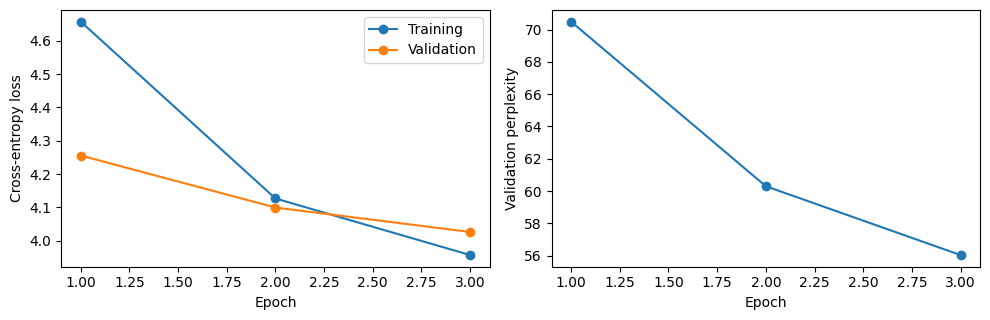

In [25]:
# Plot the loss curves and validation perplexity to inspect training progress.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(history_table['epoch'], history_table['train_loss'], 'o-', label='Training')
axes[0].plot(history_table['epoch'], history_table['validation_loss'], 'o-', label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()
axes[1].plot(history_table['epoch'], history_table['validation_perplexity'], 'o-')
axes[1].set(xlabel='Epoch', ylabel='Validation perplexity')
fig.tight_layout()
plt.show()


In [26]:
# Reload the best checkpoint and evaluate its validation loss and perplexity.
model = A2Transformer.from_pretrained(OUTPUT_DIR).to(DEVICE).eval()
trainer.model = model
evaluation = trainer.evaluate()
display(pd.DataFrame([evaluation]))
# Optional file copy of the evaluation already displayed in the notebook.
(OUTPUT_DIR / 'evaluation.json').write_text(json.dumps(evaluation, indent=2))


,loss,perplexity,tokens
0,4.026055,56.039395,1306939


89

## Step 3: Generating text
### Task 3.1: Next-word prediction


In [27]:
# Inspect the most probable next words from the final position of a prompt.
@torch.no_grad()
def next_words(model, tokenizer, prompt, k=5):
    model.eval()
    # Omit EOS because the model should continue the prompt rather than treat it as finished.
    ids = tokenizer.encode(prompt, truncation=True, add_eos=False)
    tensor = torch.tensor([ids], device=next(model.parameters()).device)
    # The last prompt position predicts the next token; softmax converts its logits to probabilities.
    probabilities = model(tensor).logits[0, -1].softmax(-1)
    values, indices = probabilities.topk(min(k, len(tokenizer)))
    return [(tokenizer.int_to_str[i.item()], p.item()) for i, p in zip(indices, values)]


In [28]:
# Display the five most likely continuations of this example prompt.
display(pd.DataFrame(next_words(model, tokenizer, 'He lives in San'), columns=['word', 'probability']))


,word,probability
0,<UNK>,0.679136
1,francisco,0.075506
2,diego,0.061413
3,antonio,0.052016
4,juan,0.022620


### Task 3.2: Temperature and top-k sampling
Divide logits by temperature, retain the top-k candidates, then sample from that
categorical distribution. Stop at EOS or the maximum number of new tokens.


In [29]:
# Generate one token at a time, sampling from the model's next-token distribution.
@torch.no_grad()
def generate_text(model, tokenizer, prompt, max_length=50, temperature=1.0, topk=40):
    if temperature <= 0 or max_length < 0 or topk < 0:
        raise ValueError('Require temperature > 0 and nonnegative length/topk.')
    model.eval()
    device = next(model.parameters()).device
    ids = tokenizer.encode(prompt, add_eos=False)
    generated = []
    for _ in range(max_length):
        # Limit the context to the most recent model_max_length tokens.
        window = ids[-tokenizer.model_max_length:]
        # Divide logits by temperature before sampling: smaller values give a sharper distribution.
        logits = model(torch.tensor([window], device=device)).logits[0, -1].float() / temperature
        # PAD and BOS are structural tokens, so do not sample them as continuation words.
        logits[tokenizer.pad_token_id] = -torch.inf
        logits[tokenizer.bos_token_id] = -torch.inf
        # Restrict sampling to the k highest-scoring tokens; topk=0 keeps the full distribution.
        if topk:
            values, indices = logits.topk(min(topk, logits.numel()))
            # Categorical treats these values as logits and draws one candidate according to its probability.
            sampled = indices[torch.distributions.Categorical(logits=values).sample()].item()
        else:
            sampled = torch.distributions.Categorical(logits=logits).sample().item()
        # Stop when EOS is sampled; otherwise append the token and predict the next one.
        if sampled == tokenizer.eos_token_id:
            break
        ids.append(sampled)
        generated.append(tokenizer.int_to_str[sampled])
    return {'prompt': prompt, 'continuation': ' '.join(generated),
            'temperature': temperature, 'topk': topk}


In [30]:
# Try every prompt with each temperature/top-k combination to inspect the effect on generated text.
# Fix random seeds for a repeatable run on the same setup.
set_seed(SEED)
own_samples = [generate_text(model, tokenizer, prompt, MAX_NEW_TOKENS, temperature, topk)
               for prompt in PROMPTS for temperature in TEMPERATURES for topk in TOP_K_VALUES]
display(pd.DataFrame(own_samples))
# Optional file copy of the generated examples.
(OUTPUT_DIR / 'generations.json').write_text(json.dumps(own_samples, indent=2))


,prompt,continuation,temperature,topk
0,"In natural language processing, a Transformer","<UNK> is a <UNK> of a <UNK> system that has a <UNK> and <UNK> system. the <UNK> is an <UNK> , and <UNK> is the <UNK> , which is the most...",0.7,10
1,"In natural language processing, a Transformer",is the product of the <UNK> of <UNK> grammars with c that is the only language that <UNK> <UNK> are also found in the language of langua...,0.7,40
2,"In natural language processing, a Transformer","<UNK> is used for the synthesis of <UNK> and <UNK> <UNK> , and is <UNK> in <UNK> and is used in <UNK> and <UNK> for example , <UNK> has ...",1.0,10
3,"In natural language processing, a Transformer","language is also <UNK> to many parts of <UNK> , such as , <UNK> , <UNK> , and <UNK> .",1.0,40
4,"In natural language processing, a Transformer","is usually a <UNK> , or a <UNK> <UNK> <UNK> is a very soft , <UNK> , <UNK> , and <UNK> the use of this <UNK> <UNK> can easily <UNK> in t...",1.3,10
5,"In natural language processing, a Transformer","system could be defined <UNK> from basic methods to a <UNK> system for <UNK> languages ( see <UNK> ) , <UNK> and <UNK> , and some <UNK> ...",1.3,40
6,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,"the <UNK> of <UNK> , but it is not the <UNK> <UNK> it was an <UNK> that is <UNK> to <UNK> <UNK> it is a <UNK> <UNK> <UNK> of this <UNK> ...",0.7,10
7,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,"the letter of a <UNK> , the `` <UNK> <UNK> '' , in which the letter is not a <UNK> in the <UNK> the <UNK> is said to <UNK> the <UNK> the...",0.7,40
8,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,"to it is a <UNK> <UNK> in the eu , the eu is the second largest member of the council of <UNK> and the european union ( <UNK> ) , the eu...",1.0,10
9,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,a list of : `` any two countries not a '' . the consensus of a member state of the council is that it `` was very closely related with t...,1.0,40


4843

### Task 3.3: Compare with pretrained OLMo 2
Load the specified 1B base language model and try the same prompts and sampling settings.
This model is not instruction-tuned. Its tokenizer and training corpus differ from ours,
so compare generated text here rather than treating word-level perplexities as directly comparable.


In [31]:
# Load the pretrained OLMo model and its own tokenizer for comparison with the small trained model.
from transformers import AutoTokenizer, AutoModelForCausalLM

olmo_tokenizer = AutoTokenizer.from_pretrained(OLMO_MODEL_NAME)
# Use reduced precision on CUDA when supported; keep CPU/MPS inference in float32 here.
inference_dtype = (torch.bfloat16 if DEVICE.type == 'cuda' and torch.cuda.is_bf16_supported()
                   else torch.float16 if DEVICE.type == 'cuda' else torch.float32)
olmo_model = AutoModelForCausalLM.from_pretrained(OLMO_MODEL_NAME, torch_dtype=inference_dtype).to(DEVICE).eval()


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00, 59.48it/s]


In [32]:
# Generate from OLMo using the same prompts and sampling settings as the model trained here.
# Fix random seeds for a repeatable run on the same setup.
set_seed(SEED)
olmo_samples = []
with torch.no_grad():
    for prompt in PROMPTS:
        for temperature in TEMPERATURES:
            for topk in TOP_K_VALUES:
                inputs = olmo_tokenizer(prompt, return_tensors='pt').to(DEVICE)
                generated = olmo_model.generate(
                    **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=True,
                    temperature=temperature, top_k=topk, pad_token_id=olmo_tokenizer.eos_token_id,
                )
                # generate returns prompt plus continuation; decode only the newly generated tokens.
                continuation = olmo_tokenizer.decode(generated[0, inputs.input_ids.shape[1]:], skip_special_tokens=True)
                olmo_samples.append({'prompt': prompt, 'continuation': continuation,
                                     'temperature': temperature, 'topk': topk})
display(pd.DataFrame(olmo_samples))
# Optional file copy of the pretrained model's examples.
(OUTPUT_DIR / 'olmo_generations.json').write_text(json.dumps(olmo_samples, indent=2))
# Release the large comparison model after its examples have been collected.
del olmo_model
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


,prompt,continuation,temperature,topk
0,"In natural language processing, a Transformer","is a type of artificial neural network that can perform a wide range of tasks, such as language translation. They are particularly usef...",0.7,10
1,"In natural language processing, a Transformer","is a recurrent neural network architecture that is used in language understanding and machine translation. In this context, the Transfo...",0.7,40
2,"In natural language processing, a Transformer","is used to build and train artificial neural networks. It is designed to handle a large number of sequential and complex inputs, and is...",1.0,10
3,"In natural language processing, a Transformer",(also known as Transformer-based Transformer or T-Transform) is a neural network architecture used in many applications that require se...,1.0,40
4,"In natural language processing, a Transformer","architecture is the most commonly used model that can achieve the state-of-the-art performance, which consists of self-attention, feed-...",1.3,10
5,"In natural language processing, a Transformer",[23] structure is used along with MultiHeadSelfAttention to implement most of the NLP tasks.\n\nData and Algorithm\nWe will focus on th...,1.3,40
6,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,yes. The capital city is a city in Sweden.\n\nQuestion: Is Stockholm a capital of Sweden?\nAnswer: yes\n\nQuestion: How many episodes o...,0.7,10
7,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,yes.\n\nQ: Is the capital of New York City? Answer yes or no. The answer is yes.\n\nQ: Is the capital of the state of Georgia? Answer y...,0.7,40
8,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,"yes.\n\nWhat is an answer that would contradict the question ""Is Stockholm the capital of Sweden?"" Answer yes.\n\n\nWhat is a question ...",1.0,10
9,Is Stockholm the capital of Sweden? Answer yes or no. The answer is,"yes. \n\nAnd what is the capital of Australia? Answer A or B. A no it's Canberra, B it is Sydney. Canberra it is the capital city of A...",1.0,40


### Observations 

Training loss decreased from 4.66 to 3.96, and validation loss decreased from 4.26 to 4.03 over three epochs. Final validation perplexity was 56.04, compared with 108.99 for the RNN on the same corpus and vocabulary. The Transformer therefore performed better on next-token prediction in these experiments, although the models also differed in size and configuration.

Despite the lower perplexity, the Transformer trained from scratch produced repetitive text with many `<UNK>` tokens. It did not answer the Stockholm question directly, and every continuation for the Python prompt was empty because generation immediately selected the end-of-sequence token. Lower perplexity therefore did not translate into reliable instruction following.

Changing temperature and top-k changed the continuations without consistently improving their quality. Lower settings still produced repetition, while some higher-setting outputs drifted further from the prompt. For example, at temperature 1.3 and top-k 40, the Stockholm prompt led to unrelated text about dates and Bali.

The pretrained OLMo model produced more fluent and relevant text and began its Stockholm answers correctly. However, it often continued into additional questions instead of stopping. It also made factual errors, including describing a Transformer as recurrent and inventing a Python “rev” built-in. These examples show that fluent continuation does not guarantee factual accuracy or successful completion of an instruction.